# Model 2 — CLIP + Small Transformer Decoder

This notebook replaces the weak LSTM/GRU caption generator with a **small Transformer decoder**.

The goal is still:

```text
best frame / thumbnail → short generated query
```

Main idea:

```text
image → frozen CLIP vision encoder → visual patch tokens → Transformer decoder → generated text
```

Important: this notebook does **not** use GPT-2 and does **not** use an API. CLIP is used only as a frozen visual feature extractor. The decoder is trained from scratch on our dataset.

## 1. Mount Google Drive

We mount Google Drive because the project data is stored inside the shared Drive folder.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Import libraries

No extra installation commands are used. This assumes Colab already has PyTorch, torchvision, transformers, pandas, and sklearn available.

In [2]:
import os
import re
import json
import math
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split

from transformers import CLIPModel, CLIPTokenizer

print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

PyTorch: 2.10.0+cu128
CUDA available: True
Device: cuda


## 3. Configuration

Change `PROJECT_DIR` only if your shared Drive folder has a different path.

The maximum caption length is kept short because our system needs a query-like sentence, not a long story.

In [3]:
# Main project folder in Google Drive
PROJECT_DIR = Path('/content/drive/MyDrive/thumbnail_project')

# Data files/folders
PAIRS_FILE = PROJECT_DIR / 'processed' / 'm2_train_pairs.jsonl'
FRAMES_DIR = PROJECT_DIR / 'qvh_frames'
EXPORT_DIR = PROJECT_DIR / 'exports' / 'model2_clip_transformer_decoder'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Model/data settings
CLIP_MODEL_NAME = 'openai/clip-vit-base-patch32'
MAX_CAPTION_WORDS = 15     # short query-style output
MIN_WORD_FREQ = 2
MAX_VOCAB_SIZE = 2000
BATCH_SIZE = 32
NUM_WORKERS = 2

# Transformer settings: intentionally small because the dataset is small
D_MODEL = 256
NHEAD = 4
NUM_DECODER_LAYERS = 2
DIM_FEEDFORWARD = 512
DROPOUT = 0.30

# Training settings
EPOCHS = 35
LR = 2e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 7
GRAD_CLIP = 1.0

# Reproducibility for training split/training. Random qualitative display later does not use a fixed sample.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Pairs file:', PAIRS_FILE)
print('Frames dir:', FRAMES_DIR)
print('Export dir:', EXPORT_DIR)

Pairs file: /content/drive/MyDrive/thumbnail_project/processed/m2_train_pairs.jsonl
Frames dir: /content/drive/MyDrive/thumbnail_project/qvh_frames
Export dir: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_transformer_decoder


## 4. Load the image-text pairs

The JSONL file contains rows like:

```json
{"frame_path": ".../qvh_frames/video_frame.jpg", "query": "..."}
```

We fix the paths so they point to the `qvh_frames` folder in Google Drive.

In [4]:
def load_jsonl(path):
    rows = []
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return rows

rows = load_jsonl(PAIRS_FILE)
df = pd.DataFrame(rows)
print('Raw rows:', len(df))
print(df.head())

# Standardize the text column name
if 'query' in df.columns:
    df['caption'] = df['query'].astype(str)
elif 'caption' in df.columns:
    df['caption'] = df['caption'].astype(str)
else:
    raise ValueError('Could not find query/caption column in the JSONL file.')

# Fix image paths: take only the filename from the original path and join it with FRAMES_DIR.
def fix_frame_path(path_value):
    filename = Path(str(path_value)).name
    return str(FRAMES_DIR / filename)

if 'frame_path' not in df.columns:
    raise ValueError('The JSONL file must contain a frame_path column.')

df['image_path'] = df['frame_path'].apply(fix_frame_path)
df['exists'] = df['image_path'].apply(lambda p: Path(p).exists())
print('Existing images:', int(df['exists'].sum()), '/', len(df))

missing = df[~df['exists']]
if len(missing) > 0:
    print('Example missing paths:')
    print(missing[['frame_path', 'image_path']].head())

df = df[df['exists']].reset_index(drop=True)
print('Usable rows:', len(df))

Raw rows: 1608
   qid                                         frame_path  \
0    1  /content/drive/MyDrive/thumbnail_project/qvh_f...   
1    6  /content/drive/MyDrive/thumbnail_project/qvh_f...   
2   11  /content/drive/MyDrive/thumbnail_project/qvh_f...   
3   16  /content/drive/MyDrive/thumbnail_project/qvh_f...   
4   27  /content/drive/MyDrive/thumbnail_project/qvh_f...   

                                              query                      vid  \
0  Woman wears a white top walking down the street.  Q2TqU-Oh7KQ_360.0_510.0   
1                 A woman is introducing her family  9c_w8HU3hqc_360.0_510.0   
2        Blonde woman is walking up a grassy field.  0gzFURbCXoE_210.0_360.0   
3                       Man is leaning with a boat.   u-61297MT1I_60.0_210.0   
4                   Video shows the Bluetooth sign.  t_9gaLdfc_Y_210.0_360.0   

   best_timestamp  mean_saliency  
0              73          3.667  
1             103          3.667  
2               9          3.333

## 5. Clean captions

We clean the target text and keep it short. This reduces the chance of the decoder generating long story-like outputs.

In [5]:
def clean_caption(text):
    text = str(text).lower().strip()
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    words = text.split()[:MAX_CAPTION_WORDS]
    return ' '.join(words)

df['clean_caption'] = df['caption'].apply(clean_caption)
df = df[df['clean_caption'].str.len() > 0].reset_index(drop=True)

print('Rows after cleaning:', len(df))
for i in range(5):
    print('-', df.loc[i, 'clean_caption'])

Rows after cleaning: 1608
- woman wears a white top walking down the street
- a woman is introducing her family
- blonde woman is walking up a grassy field
- man is leaning with a boat
- video shows the bluetooth sign


## 6. Train/validation/test split

We split the pairs into training, validation, and test sets.

In [6]:
train_df, temp_df = train_test_split(df, test_size=0.20, random_state=SEED, shuffle=True)
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, shuffle=True)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print('Train:', len(train_df))
print('Val  :', len(val_df))
print('Test :', len(test_df))

Train: 1286
Val  : 161
Test : 161


## 7. Build vocabulary

The Transformer decoder predicts words from this vocabulary. Rare words are mapped to `<UNK>` to reduce overfitting.

In [7]:
SPECIAL_TOKENS = ['<PAD>', '<SOS>', '<EOS>', '<UNK>']
PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN = SPECIAL_TOKENS

counter = Counter()
for cap in train_df['clean_caption']:
    counter.update(cap.split())

words = [w for w, c in counter.items() if c >= MIN_WORD_FREQ]
words = sorted(words, key=lambda w: (-counter[w], w))[:MAX_VOCAB_SIZE - len(SPECIAL_TOKENS)]

itos = SPECIAL_TOKENS + words
stoi = {w: i for i, w in enumerate(itos)}

PAD_IDX = stoi[PAD_TOKEN]
SOS_IDX = stoi[SOS_TOKEN]
EOS_IDX = stoi[EOS_TOKEN]
UNK_IDX = stoi[UNK_TOKEN]

print('Vocabulary size:', len(itos))
print('Most common words:', counter.most_common(20))

# Save vocab for later inference
vocab_path = EXPORT_DIR / 'vocab.json'
with open(vocab_path, 'w', encoding='utf-8') as f:
    json.dump({'itos': itos, 'stoi': stoi}, f, indent=2)
print('Saved vocab to:', vocab_path)

Vocabulary size: 957
Most common words: [('a', 1460), ('in', 530), ('the', 460), ('woman', 429), ('and', 301), ('is', 295), ('of', 271), ('man', 248), ('on', 212), ('her', 173), ('with', 168), ('to', 161), ('are', 123), ('at', 106), ('talking', 82), ('white', 81), ('black', 78), ('girl', 77), ('two', 73), ('up', 71)]
Saved vocab to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_transformer_decoder/vocab.json


## 8. Encode captions

For training, the decoder input is:

```text
<SOS> word1 word2 ...
```

The target is:

```text
word1 word2 ... <EOS>
```

In [8]:
MAX_SEQ_LEN = MAX_CAPTION_WORDS + 2  # <SOS> + words + <EOS>

def encode_caption(caption):
    words = caption.split()[:MAX_CAPTION_WORDS]
    ids = [stoi.get(w, UNK_IDX) for w in words]

    decoder_input = [SOS_IDX] + ids
    target = ids + [EOS_IDX]

    decoder_input = decoder_input[:MAX_SEQ_LEN]
    target = target[:MAX_SEQ_LEN]

    while len(decoder_input) < MAX_SEQ_LEN:
        decoder_input.append(PAD_IDX)
    while len(target) < MAX_SEQ_LEN:
        target.append(PAD_IDX)

    return torch.tensor(decoder_input, dtype=torch.long), torch.tensor(target, dtype=torch.long)

def decode_ids(ids):
    words = []
    for idx in ids:
        idx = int(idx)
        if idx == EOS_IDX:
            break
        if idx in [PAD_IDX, SOS_IDX]:
            continue
        words.append(itos[idx] if idx < len(itos) else UNK_TOKEN)
    return ' '.join(words)

sample_inp, sample_tgt = encode_caption(train_df.loc[0, 'clean_caption'])
print('Caption:', train_df.loc[0, 'clean_caption'])
print('Input IDs:', sample_inp[:10].tolist())
print('Target IDs:', sample_tgt[:10].tolist())
print('Decoded target:', decode_ids(sample_tgt))

Caption: a woman in a black hat tries curry with hamburger spice level 3 at coco
Input IDs: [1, 4, 7, 5, 4, 20, 205, 289, 479, 14]
Target IDs: [4, 7, 5, 4, 20, 205, 289, 479, 14, 729]
Decoded target: a woman in a black hat tries curry with hamburger <UNK> level <UNK> at <UNK>


## 9. Image preprocessing and dataset

We use light augmentation only on training images. We avoid horizontal flipping because some frames/thumbnails may contain text.

In [9]:
CLIP_MEAN = [0.48145466, 0.4578275, 0.40821073]
CLIP_STD = [0.26862954, 0.26130258, 0.27577711]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.03),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    transforms.Normalize(mean=CLIP_MEAN, std=CLIP_STD),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=CLIP_MEAN, std=CLIP_STD),
])

class FrameCaptionDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        image = self.transform(image)
        decoder_input, target = encode_caption(row['clean_caption'])

        return {
            'image': image,
            'decoder_input': decoder_input,
            'target': target,
            'clean_caption': row['clean_caption'],
            'image_path': row['image_path'],
        }

train_dataset = FrameCaptionDataset(train_df, train_transform)
val_dataset = FrameCaptionDataset(val_df, val_transform)
test_dataset = FrameCaptionDataset(test_df, val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

batch = next(iter(train_loader))
print('Image batch:', batch['image'].shape)
print('Decoder input batch:', batch['decoder_input'].shape)
print('Target batch:', batch['target'].shape)

Image batch: torch.Size([32, 3, 224, 224])
Decoder input batch: torch.Size([32, 17])
Target batch: torch.Size([32, 17])


## 10. Load frozen CLIP vision encoder

We extract **visual patch tokens** from CLIP, not only one pooled image vector. This gives the Transformer decoder more visual information to attend to.

In [10]:
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(device)
clip_model.eval()

for param in clip_model.parameters():
    param.requires_grad = False

@torch.no_grad()
def extract_clip_visual_tokens(pixel_values):
    """
    Returns CLIP vision tokens.
    Shape: [batch, num_tokens, visual_dim]
    For ViT-B/32, num_tokens is usually 50 = 1 CLS token + 49 patch tokens.
    """
    pixel_values = pixel_values.to(device)
    vision_outputs = clip_model.vision_model(pixel_values=pixel_values)

    # The robust path: last_hidden_state contains CLS + patch tokens.
    if hasattr(vision_outputs, 'last_hidden_state'):
        return vision_outputs.last_hidden_state

    # Fallback if a tuple is returned.
    if isinstance(vision_outputs, (tuple, list)):
        return vision_outputs[0]

    raise TypeError(f'Unexpected CLIP vision output type: {type(vision_outputs)}')

with torch.no_grad():
    dummy = torch.zeros(2, 3, 224, 224).to(device)
    dummy_tokens = extract_clip_visual_tokens(dummy)

VISUAL_DIM = dummy_tokens.shape[-1]
NUM_VISUAL_TOKENS = dummy_tokens.shape[1]
print('CLIP visual tokens shape:', dummy_tokens.shape)
print('Visual dim:', VISUAL_DIM)
print('Number of visual tokens:', NUM_VISUAL_TOKENS)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

CLIP visual tokens shape: torch.Size([2, 50, 768])
Visual dim: 768
Number of visual tokens: 50


## 11. Positional encoding

The Transformer decoder needs positional information because attention alone does not know word order.

In [11]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # [1, max_len, d_model]
        self.register_buffer('pe', pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

## 12. CLIP + Transformer decoder model

The decoder uses:

- word embeddings
- positional encoding
- masked self-attention over generated words
- cross-attention to CLIP visual tokens
- a linear layer over the vocabulary

In [12]:
class CLIPTransformerCaptioner(nn.Module):
    def __init__(self, vocab_size, visual_dim, d_model=256, nhead=4,
                 num_layers=2, dim_feedforward=512, dropout=0.3):
        super().__init__()
        self.d_model = d_model

        self.visual_proj = nn.Linear(visual_dim, d_model)
        self.token_embed = nn.Embedding(vocab_size, d_model, padding_idx=PAD_IDX)
        self.pos_encoder = PositionalEncoding(d_model, max_len=MAX_SEQ_LEN + 5)
        self.dropout = nn.Dropout(dropout)

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            activation='gelu'
        )
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_layers)
        self.output_fc = nn.Linear(d_model, vocab_size)

    def make_causal_mask(self, seq_len, device):
        # True means masked position in PyTorch Transformer.
        mask = torch.triu(torch.ones(seq_len, seq_len, device=device, dtype=torch.bool), diagonal=1)
        return mask

    def forward(self, visual_tokens, decoder_input):
        # visual_tokens: [B, Nv, visual_dim]
        # decoder_input: [B, T]
        memory = self.visual_proj(visual_tokens)  # [B, Nv, d_model]

        tgt = self.token_embed(decoder_input) * math.sqrt(self.d_model)
        tgt = self.pos_encoder(tgt)
        tgt = self.dropout(tgt)

        T = decoder_input.size(1)
        causal_mask = self.make_causal_mask(T, decoder_input.device)
        tgt_padding_mask = decoder_input.eq(PAD_IDX)

        out = self.decoder(
            tgt=tgt,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=tgt_padding_mask
        )
        logits = self.output_fc(out)  # [B, T, vocab_size]
        return logits

model = CLIPTransformerCaptioner(
    vocab_size=len(itos),
    visual_dim=VISUAL_DIM,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
).to(device)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Trainable Transformer decoder parameters:', f'{num_params:,}')

Trainable Transformer decoder parameters: 2,269,373


## 13. Training and validation functions

We use teacher forcing: during training, the decoder receives the ground-truth previous words.

In [13]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, label_smoothing=0.05)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)


def run_one_epoch(model, loader, train=True):
    model.train() if train else model.eval()
    total_loss = 0.0
    total_tokens = 0

    for batch in loader:
        images = batch['image'].to(device, non_blocking=True)
        decoder_input = batch['decoder_input'].to(device, non_blocking=True)
        target = batch['target'].to(device, non_blocking=True)

        with torch.no_grad():
            visual_tokens = extract_clip_visual_tokens(images)

        if train:
            optimizer.zero_grad(set_to_none=True)

        logits = model(visual_tokens, decoder_input)
        loss = criterion(logits.reshape(-1, logits.size(-1)), target.reshape(-1))

        if train:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()

        non_pad = target.ne(PAD_IDX).sum().item()
        total_loss += loss.item() * non_pad
        total_tokens += non_pad

    return total_loss / max(total_tokens, 1)

## 14. Train the Transformer decoder

The best checkpoint is saved based on validation loss.

In [14]:
best_val_loss = float('inf')
best_epoch = -1
bad_epochs = 0
history = {'train_loss': [], 'val_loss': []}
best_model_path = EXPORT_DIR / 'best_clip_transformer_decoder.pt'

for epoch in range(1, EPOCHS + 1):
    train_loss = run_one_epoch(model, train_loader, train=True)
    val_loss = run_one_epoch(model, val_loader, train=False)
    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)

    print(f'Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}')

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        bad_epochs = 0
        torch.save({
            'model_state_dict': model.state_dict(),
            'config': {
                'vocab_size': len(itos),
                'visual_dim': VISUAL_DIM,
                'd_model': D_MODEL,
                'nhead': NHEAD,
                'num_layers': NUM_DECODER_LAYERS,
                'dim_feedforward': DIM_FEEDFORWARD,
                'dropout': DROPOUT,
                'max_caption_words': MAX_CAPTION_WORDS,
                'clip_model_name': CLIP_MODEL_NAME,
            },
            'itos': itos,
            'stoi': stoi,
            'history': history,
        }, best_model_path)
        print('  Saved best model to:', best_model_path)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f'Early stopping at epoch {epoch}. Best epoch: {best_epoch}.')
            break

print('Training finished.')
print('Best validation loss:', best_val_loss)
print('Best epoch:', best_epoch)

Epoch 01/35 | Train Loss: 5.6316 | Val Loss: 4.8198
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_transformer_decoder/best_clip_transformer_decoder.pt
Epoch 02/35 | Train Loss: 4.9448 | Val Loss: 4.5722
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_transformer_decoder/best_clip_transformer_decoder.pt
Epoch 03/35 | Train Loss: 4.7704 | Val Loss: 4.4127
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_transformer_decoder/best_clip_transformer_decoder.pt
Epoch 04/35 | Train Loss: 4.6416 | Val Loss: 4.3073
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_transformer_decoder/best_clip_transformer_decoder.pt
Epoch 05/35 | Train Loss: 4.5270 | Val Loss: 4.2175
  Saved best model to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_transformer_decoder/best_clip_transformer_decoder.pt
Epoch 06/35 | Train Loss: 4.4265 | Val Loss: 4.1445
  S

## 15. Plot the training curves

If training loss decreases but validation loss does not improve, the model is overfitting.

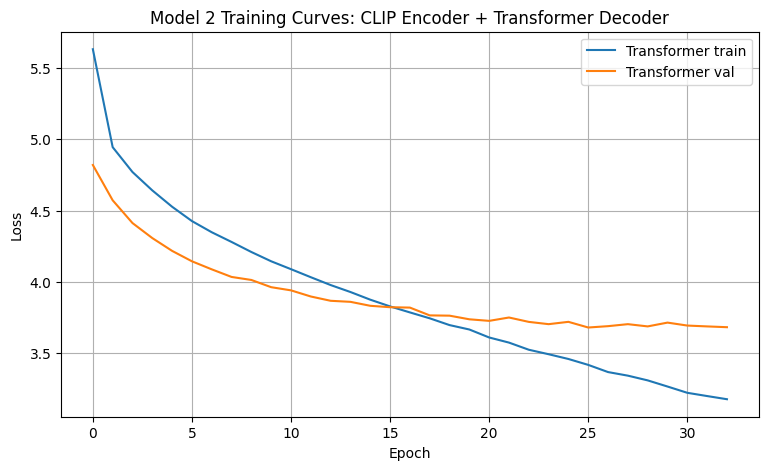

In [15]:
plt.figure(figsize=(9, 5))
plt.plot(history['train_loss'], label='Transformer train')
plt.plot(history['val_loss'], label='Transformer val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Model 2 Training Curves: CLIP Encoder + Transformer Decoder')
plt.grid(True)
plt.legend()
plt.show()

## 16. Load the best checkpoint

We evaluate and generate captions using the best validation checkpoint, not necessarily the last epoch.

In [16]:
checkpoint = torch.load(best_model_path, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print('Loaded best model from:', best_model_path)
print('Best epoch:', checkpoint.get('history', {}).get('best_epoch', 'stored in printed output above'))

Loaded best model from: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_transformer_decoder/best_clip_transformer_decoder.pt
Best epoch: stored in printed output above


## 17. Greedy and beam-search decoding

Greedy decoding chooses the best next word at every step. Beam search keeps multiple possible sentences and often gives better outputs.

In [17]:
@torch.no_grad()
def generate_greedy(image_tensor, max_words=MAX_CAPTION_WORDS):
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)
    visual_tokens = extract_clip_visual_tokens(image_tensor)

    generated = [SOS_IDX]

    for _ in range(max_words):
        inp = torch.tensor(generated, dtype=torch.long, device=device).unsqueeze(0)
        logits = model(visual_tokens, inp)
        next_logits = logits[0, -1, :].clone()

        # Avoid invalid tokens during generation.
        next_logits[PAD_IDX] = -1e9
        next_logits[SOS_IDX] = -1e9
        next_logits[UNK_IDX] = -1e9

        next_id = int(torch.argmax(next_logits).item())
        if next_id == EOS_IDX:
            break
        generated.append(next_id)

    return decode_ids(generated[1:])


@torch.no_grad()
def generate_beam(image_tensor, beam_width=3, max_words=MAX_CAPTION_WORDS):
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)
    visual_tokens = extract_clip_visual_tokens(image_tensor)

    beams = [([SOS_IDX], 0.0)]  # (tokens, log_prob)

    for _ in range(max_words):
        new_beams = []
        for tokens, score in beams:
            if tokens[-1] == EOS_IDX:
                new_beams.append((tokens, score))
                continue

            inp = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)
            logits = model(visual_tokens, inp)
            next_logits = logits[0, -1, :].clone()

            next_logits[PAD_IDX] = -1e9
            next_logits[SOS_IDX] = -1e9
            next_logits[UNK_IDX] = -1e9

            log_probs = torch.log_softmax(next_logits, dim=-1)
            top_log_probs, top_ids = torch.topk(log_probs, beam_width)

            for lp, idx in zip(top_log_probs.tolist(), top_ids.tolist()):
                new_beams.append((tokens + [int(idx)], score + float(lp)))

        # Length-normalized score to avoid always preferring very short outputs.
        beams = sorted(new_beams, key=lambda x: x[1] / max(len(x[0]), 1), reverse=True)[:beam_width]

        if all(tokens[-1] == EOS_IDX for tokens, _ in beams):
            break

    best_tokens = beams[0][0][1:]  # remove SOS
    return decode_ids(best_tokens)

## 18. Simple metrics: BLEU-1 and ROUGE-L

These metrics are limited, but they give a rough automatic comparison.

In [18]:
def bleu1(reference, prediction):
    ref_words = reference.split()
    pred_words = prediction.split()
    if len(pred_words) == 0:
        return 0.0
    ref_counts = Counter(ref_words)
    overlap = 0
    for w in pred_words:
        if ref_counts[w] > 0:
            overlap += 1
            ref_counts[w] -= 1
    precision = overlap / len(pred_words)
    brevity = min(1.0, math.exp(1 - len(ref_words) / max(len(pred_words), 1)))
    return brevity * precision


def lcs_length(a, b):
    dp = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            if a[i - 1] == b[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])
    return dp[-1][-1]


def rouge_l(reference, prediction):
    ref_words = reference.split()
    pred_words = prediction.split()
    if len(ref_words) == 0 or len(pred_words) == 0:
        return 0.0
    lcs = lcs_length(ref_words, pred_words)
    recall = lcs / len(ref_words)
    precision = lcs / len(pred_words)
    if recall + precision == 0:
        return 0.0
    return 2 * recall * precision / (recall + precision)


@torch.no_grad()
def evaluate_generator(dataset, method='beam', max_items=None):
    refs, preds = [], []
    n = len(dataset) if max_items is None else min(len(dataset), max_items)
    for i in range(n):
        item = dataset[i]
        if method == 'greedy':
            pred = generate_greedy(item['image'])
        else:
            pred = generate_beam(item['image'], beam_width=3)
        ref = item['clean_caption']
        refs.append(ref)
        preds.append(pred)

    return {
        'BLEU-1': float(np.mean([bleu1(r, p) for r, p in zip(refs, preds)])),
        'ROUGE-L': float(np.mean([rouge_l(r, p) for r, p in zip(refs, preds)])),
        'refs': refs,
        'preds': preds,
    }

print('Metric functions ready.')

Metric functions ready.


## 19. CLIP retrieval baseline

Retrieval does not generate a new sentence. It chooses the closest existing caption from the training bank using CLIP image-text similarity.

This is useful as a baseline because our dataset is small and many targets are not fully visible in the image.

In [19]:
clip_tokenizer = CLIPTokenizer.from_pretrained(CLIP_MODEL_NAME)

@torch.no_grad()
def extract_clip_projected_image_features(pixel_values):
    output = clip_model.get_image_features(pixel_values=pixel_values.to(device))

    if torch.is_tensor(output):
        feats = output
    elif hasattr(output, 'image_embeds'):
        feats = output.image_embeds
    else:
        vision_outputs = clip_model.vision_model(pixel_values=pixel_values.to(device))
        pooled = vision_outputs.pooler_output
        feats = clip_model.visual_projection(pooled) if hasattr(clip_model, 'visual_projection') else pooled

    feats = feats / feats.norm(dim=-1, keepdim=True).clamp(min=1e-8)
    return feats


@torch.no_grad()
def extract_clip_projected_text_features(tokens):
    output = clip_model.get_text_features(**tokens)

    if torch.is_tensor(output):
        feats = output
    elif hasattr(output, 'text_embeds'):
        feats = output.text_embeds
    else:
        text_outputs = clip_model.text_model(
            input_ids=tokens['input_ids'],
            attention_mask=tokens['attention_mask']
        )
        pooled = text_outputs.pooler_output
        feats = clip_model.text_projection(pooled) if hasattr(clip_model, 'text_projection') else pooled

    feats = feats / feats.norm(dim=-1, keepdim=True).clamp(min=1e-8)
    return feats


@torch.no_grad()
def get_clip_text_features(texts, batch_size=64):
    all_features = []
    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]
        tokens = clip_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=77,
            return_tensors='pt'
        ).to(device)
        feats = extract_clip_projected_text_features(tokens)
        all_features.append(feats.cpu())
    return torch.cat(all_features, dim=0)

retrieval_captions = sorted(train_df['clean_caption'].dropna().unique().tolist())
print('Retrieval caption bank size:', len(retrieval_captions))
retrieval_text_features = get_clip_text_features(retrieval_captions).to(device)
print('Text feature matrix:', retrieval_text_features.shape)


@torch.no_grad()
def retrieve_caption(image_tensor, top_k=3):
    image_features = extract_clip_projected_image_features(image_tensor.unsqueeze(0).to(device))
    sims = image_features @ retrieval_text_features.T
    top = torch.topk(sims.squeeze(0), k=top_k)
    indices = top.indices.cpu().tolist()
    scores = top.values.cpu().tolist()
    return [(retrieval_captions[i], scores[j]) for j, i in enumerate(indices)]


def evaluate_retrieval(dataset):
    refs, preds = [], []
    for i in range(len(dataset)):
        item = dataset[i]
        pred = retrieve_caption(item['image'], top_k=1)[0][0]
        ref = item['clean_caption']
        refs.append(ref)
        preds.append(pred)
    return {
        'BLEU-1': float(np.mean([bleu1(r, p) for r, p in zip(refs, preds)])),
        'ROUGE-L': float(np.mean([rouge_l(r, p) for r, p in zip(refs, preds)])),
        'refs': refs,
        'preds': preds,
    }

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Retrieval caption bank size: 1286
Text feature matrix: torch.Size([1286, 512])


## 20. Evaluate Transformer and retrieval

This compares generated text against the retrieval baseline.

In [20]:
transformer_greedy_results = evaluate_generator(test_dataset, method='greedy')
transformer_beam_results = evaluate_generator(test_dataset, method='beam')
retrieval_results = evaluate_retrieval(test_dataset)

comparison = pd.DataFrame([
    {
        'Method': 'CLIP + Transformer Decoder (Greedy)',
        'BLEU-1': transformer_greedy_results['BLEU-1'],
        'ROUGE-L': transformer_greedy_results['ROUGE-L'],
    },
    {
        'Method': 'CLIP + Transformer Decoder (Beam)',
        'BLEU-1': transformer_beam_results['BLEU-1'],
        'ROUGE-L': transformer_beam_results['ROUGE-L'],
    },
    {
        'Method': 'CLIP Retrieval Baseline',
        'BLEU-1': retrieval_results['BLEU-1'],
        'ROUGE-L': retrieval_results['ROUGE-L'],
    },
])

print(comparison)
comparison_path = EXPORT_DIR / 'transformer_comparison.csv'
comparison.to_csv(comparison_path, index=False)
print('Saved comparison to:', comparison_path)

                                Method    BLEU-1   ROUGE-L
0  CLIP + Transformer Decoder (Greedy)  0.174713  0.190081
1    CLIP + Transformer Decoder (Beam)  0.180678  0.198864
2              CLIP Retrieval Baseline  0.134487  0.148048
Saved comparison to: /content/drive/MyDrive/thumbnail_project/exports/model2_clip_transformer_decoder/transformer_comparison.csv


## 21. Show random qualitative examples

Every time you run this cell, it samples different test images.

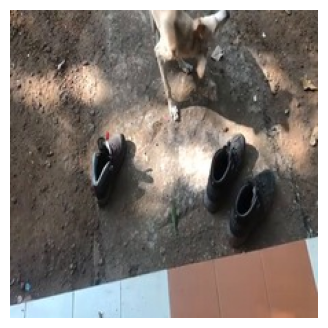

GT          : vlogger shows the shoes on the floor then picks some up
Transformer Greedy: a woman is showing a large white top is showing a large white top is
Transformer Beam  : a woman is showing the beach
Retrieval          : woman unleashes the dog to play catch with them  (score=0.276)
Top 3 retrieval options:
  1. woman unleashes the dog to play catch with them | score=0.276
  2. a man is squatting and taking care of a horse s feet | score=0.269
  3. dogs are excited as they are getting christmas gifts | score=0.269
----------------------------------------------------------------------------------------------------


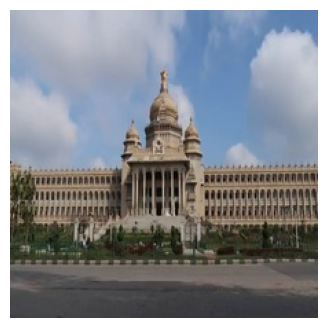

GT          : a video capture of ancient buildings in bangalore
Transformer Greedy: a man in a black top is talking to the camera and shows off a
Transformer Beam  : a man in a black top is talking to the camera in the camera and
Retrieval          : tourist girl sharing amazing footage of historical buildings  (score=0.256)
Top 3 retrieval options:
  1. tourist girl sharing amazing footage of historical buildings | score=0.256
  2. my tour to a beautiful housing society | score=0.247
  3. news on protests and unrest for past curfew is shown | score=0.245
----------------------------------------------------------------------------------------------------


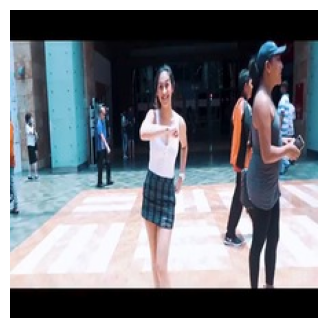

GT          : asian girl having fun in hotel lobby in indonesia
Transformer Greedy: a woman in a black top is talking to the camera and talks about the
Transformer Beam  : a woman in a black top is talking to the camera in front of a
Retrieval          : girl showing different university department buildings  (score=0.307)
Top 3 retrieval options:
  1. girl showing different university department buildings | score=0.307
  2. a student continues vlogging as she enters her high school | score=0.304
  3. school girls having fun during study | score=0.303
----------------------------------------------------------------------------------------------------


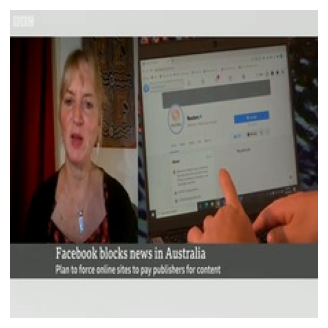

GT          : blonde woman speaks to the left of the screen while the right is a computer
Transformer Greedy: a woman is talking about her hair is talking about her hair
Transformer Beam  : a woman in white top is talking to the camera in front of the camera
Retrieval          : blonde woman has a map behind her while she s being interviewed  (score=0.291)
Top 3 retrieval options:
  1. blonde woman has a map behind her while she s being interviewed | score=0.291
  2. computer screen tells the viewers to subscribe | score=0.283
  3. woman uses a stylus on the tablet | score=0.282
----------------------------------------------------------------------------------------------------


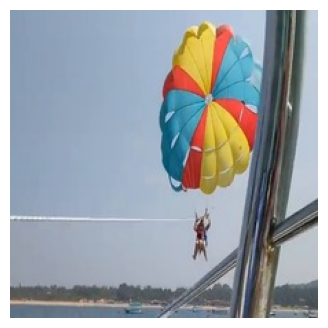

GT          : a little girl tries parasailing on a windy overcast day
Transformer Greedy: a man in a red top is walking through a large white
Transformer Beam  : a man in a black t shirt is talking in a black t shirt is
Retrieval          : a video showing a kid in a zipline  (score=0.287)
Top 3 retrieval options:
  1. a video showing a kid in a zipline | score=0.287
  2. a woman describes another attraction in brazil s in cabo frio that is now as | score=0.283
  3. a man in a ball cap and red shirt holds his toddler in the air | score=0.282
----------------------------------------------------------------------------------------------------


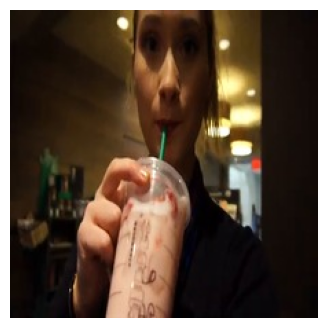

GT          : a flight attendant gets a delicious fruit drink before her long day at work
Transformer Greedy: a woman is showing her hotel room
Transformer Beam  : a woman in a black top is talking to the camera in the camera
Retrieval          : a young woman with glasses is amazed at the amount of ice coffee she sees  (score=0.332)
Top 3 retrieval options:
  1. a young woman with glasses is amazed at the amount of ice coffee she sees | score=0.332
  2. woman vlogs while holding a drink with whipped cream | score=0.315
  3. woman picks up a starbucks mug then shows it off | score=0.311
----------------------------------------------------------------------------------------------------


In [21]:
def denormalize_image(tensor):
    mean = torch.tensor(CLIP_MEAN).view(3, 1, 1)
    std = torch.tensor(CLIP_STD).view(3, 1, 1)
    img = tensor.cpu() * std + mean
    img = img.clamp(0, 1)
    return img.permute(1, 2, 0).numpy()


def show_random_examples(dataset, n=6):
    indices = random.sample(range(len(dataset)), k=min(n, len(dataset)))

    for idx in indices:
        item = dataset[idx]
        image = item['image']
        gt = item['clean_caption']
        greedy = generate_greedy(image)
        beam = generate_beam(image, beam_width=3)
        retrieval_top3 = retrieve_caption(image, top_k=3)

        plt.figure(figsize=(4, 4))
        plt.imshow(denormalize_image(image))
        plt.axis('off')
        plt.show()

        print('GT          :', gt)
        print('Transformer Greedy:', greedy)
        print('Transformer Beam  :', beam)
        print(f'Retrieval          : {retrieval_top3[0][0]}  (score={retrieval_top3[0][1]:.3f})')
        print('Top 3 retrieval options:')
        for rank, (cap, score) in enumerate(retrieval_top3, start=1):
            print(f'  {rank}. {cap} | score={score:.3f}')
        print('-' * 100)

show_random_examples(test_dataset, n=6)